<div style="text-align:center">
Министерство науки и высшего образования Российской Федерации<br>
Федеральное государственное бюджетное образовательное учреждение высшего образования<br>
Уфимский университет науки и технологии<br>Кафедра АСУ

# Отчёт по практической работе №5
## Разведочный анализ данных (EDA) на Python
по дисциплине «Интеллектуальные информационные системы»

Выполнил: ст. гр. ЭАС-401С Вахапов А.А.<br>Проверяющий: Насыров Р.В.<br>Уфа 2026
</div>

## Введение и цель
Освоить загрузку, первичное исследование, статистическое описание и визуализацию
данных на Python. Исследуется California Housing: районы Калифорнии по переписи
1990 года. Единица наблюдения — группа кварталов, а не отдельный дом.
Исследование описательное; корреляции не доказывают причинного влияния.

## 1. Загрузка и первичный осмотр
Используются pandas, NumPy, Matplotlib, Seaborn, SciPy и scikit-learn.
Данные загружаются через `fetch_california_housing`; при повторном запуске
используется локальный кэш. Все результаты и изображения создаются ячейками ниже.

In [1]:
from pathlib import Path
import hashlib
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.stats.mstats import winsorize
from sklearn.datasets import fetch_california_housing
from IPython.display import display, Markdown

BASE = Path.cwd()
FIGURES = BASE / "figures"
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.9)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})
housing = fetch_california_housing(data_home=str(BASE / "data/sklearn_cache"), as_frame=True, download_if_missing=False)
df = housing.frame.copy()
original_columns = df.columns.tolist()
labels = {
    "MedInc": "MedInc, 10 тыс. долларов", "HouseAge": "HouseAge, лет",
    "AveRooms": "AveRooms, комнат/домохозяйство", "AveBedrms": "AveBedrms, спален/домохозяйство",
    "Population": "Population, человек", "AveOccup": "AveOccup, человек/домохозяйство",
    "Latitude": "Latitude, градусы", "Longitude": "Longitude, градусы",
    "MedHouseVal": "MedHouseVal, 100 тыс. долларов",
}

def save_figure(fig, stem):
    for suffix in ("png", "svg"):
        fig.savefig(FIGURES / f"{stem}.{suffix}", dpi=160, bbox_inches="tight", facecolor="white", transparent=False)
    plt.show()
    plt.close(fig)

print("Размерность:", df.shape)
display(df.head())
df.info()
display(df.isna().sum().rename("Пропусков").to_frame())
assert df.shape == (20640, 9)
assert np.isfinite(df.to_numpy()).all()
print("Полных дубликатов:", int(df.duplicated().sum()))

Размерность: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,Пропусков
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Полных дубликатов: 0


**Описание переменных.** MedInc — медианный доход в десятках тысяч долларов;
HouseAge — **медианный**, а не средний возраст домов в районе; AveRooms и AveBedrms —
среднее число комнат и спален на домохозяйство; Population — население района;
AveOccup — среднее число жителей на домохозяйство; Latitude и Longitude — координаты
в градусах; MedHouseVal — медианная стоимость дома в сотнях тысяч долларов.

**Качество данных.** Пропуски проверены по каждому столбцу. При их отсутствии
импутация не применяется. При наличии пропусков сначала следует изучить причины,
затем обосновать исключение записей или заполнение, например медианой.

## 2. Описательная статистика
Квартили вычисляются линейной интерполяцией pandas; стандартное отклонение —
выборочное с `ddof=1`. Асимметрия и эксцесс вычисляются `skew()` и `kurt()` pandas
с поправками на объём выборки. Нормальному распределению соответствует эксцесс ноль.

In [2]:
summary = df.describe().T.rename(columns={"std": "std_sample", "25%": "q1", "50%": "median", "75%": "q3"})
summary["skewness"] = df.skew()
summary["excess_kurtosis"] = df.kurt()
display(summary.round(6))
summary.to_csv(BASE / "descriptive_statistics.csv", index_label="variable")
display(Markdown("Среднее и медиана расходятся у скошенных признаков. "
    "Наибольшая асимметрия у **" + summary.skewness.idxmax() + "**: "
    + f"{summary.skewness.max():.3f}. Поэтому средние следует оценивать вместе с медианами и квартилями."))

,count,mean,std_sample,min,q1,median,q3,max,skewness,excess_kurtosis
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100,1.646657,4.952524
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000,0.060331,-0.800629
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091,20.697869,879.353264
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667,31.316956,1636.711972
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000,4.935858,73.553116
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333,97.639561,10651.010636
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000,0.465953,-1.117760
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000,-0.297801,-1.330152
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010,0.977763,0.327870


Среднее и медиана расходятся у скошенных признаков. Наибольшая асимметрия у **AveOccup**: 97.640. Поэтому средние следует оценивать вместе с медианами и квартилями.

## 3. Распределения
Гистограммы используют все наблюдения. Логарифмическая шкала частот позволяет
показать редкие крайние значения; сами данные не преобразуются.
На ящиках с усами выбросы показаны точками. Для сильно скошенных положительных
признаков применяется логарифмическая шкала горизонтальной оси, явно указанная в подписи.

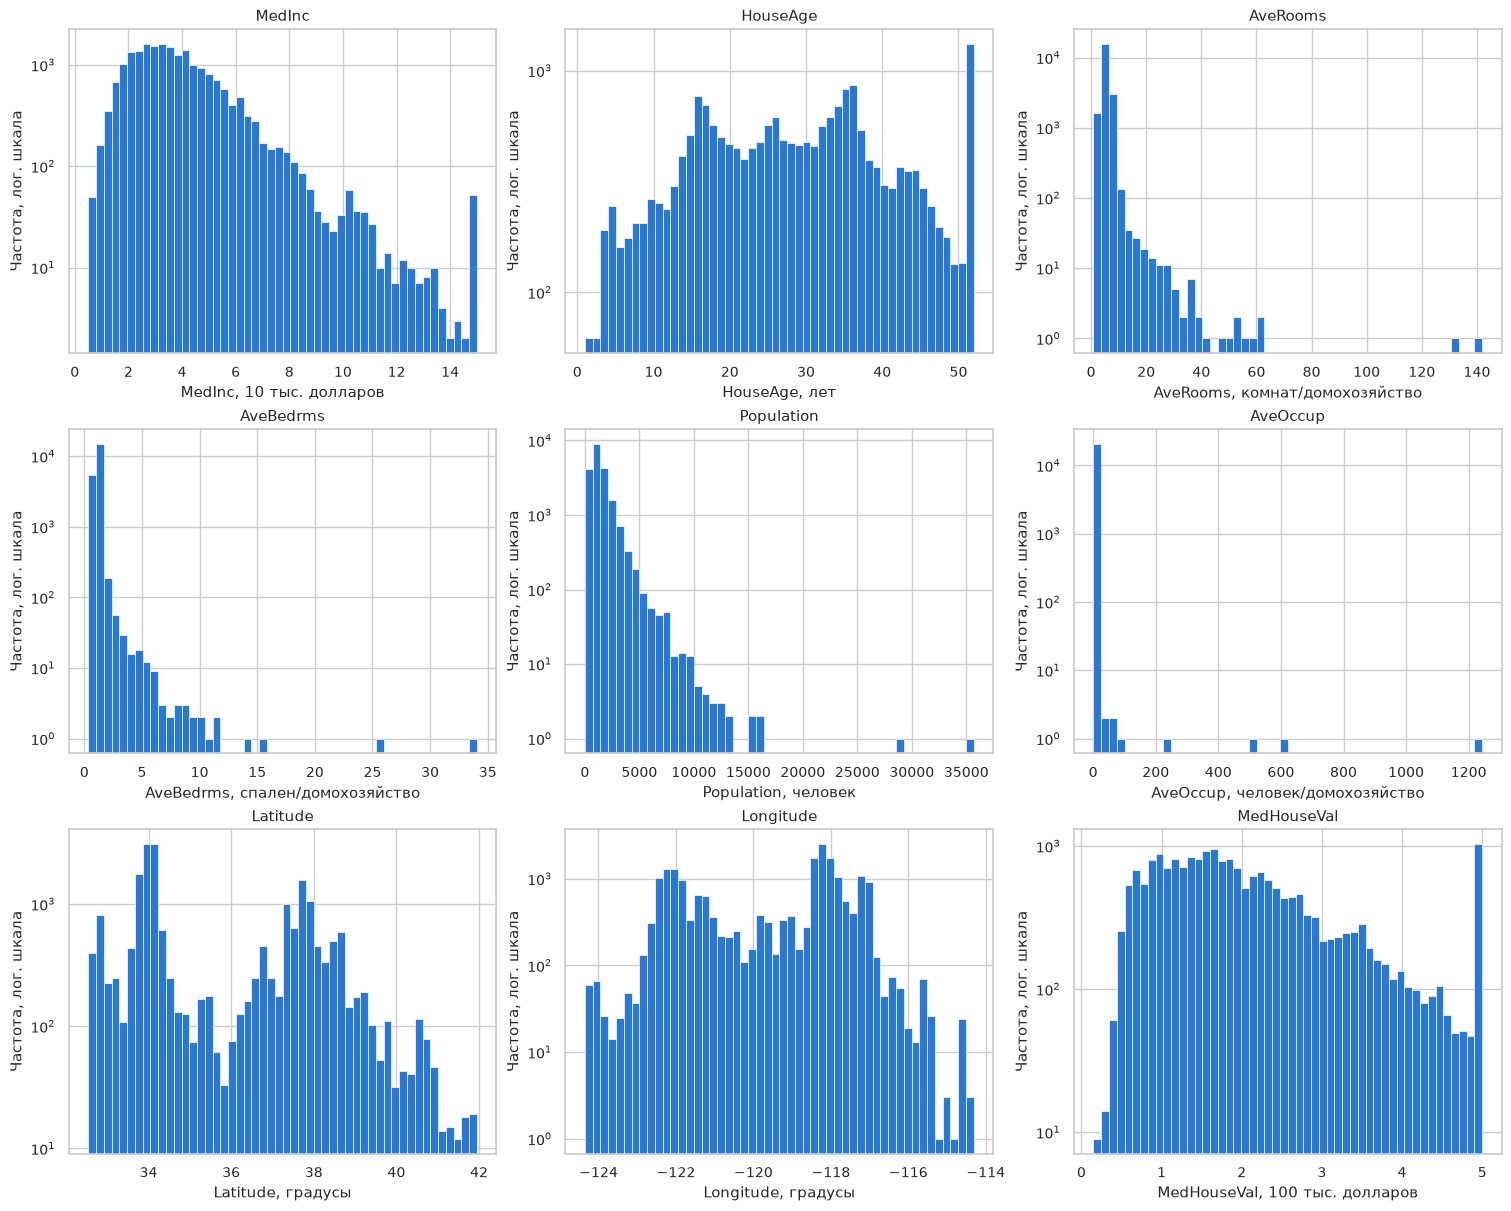

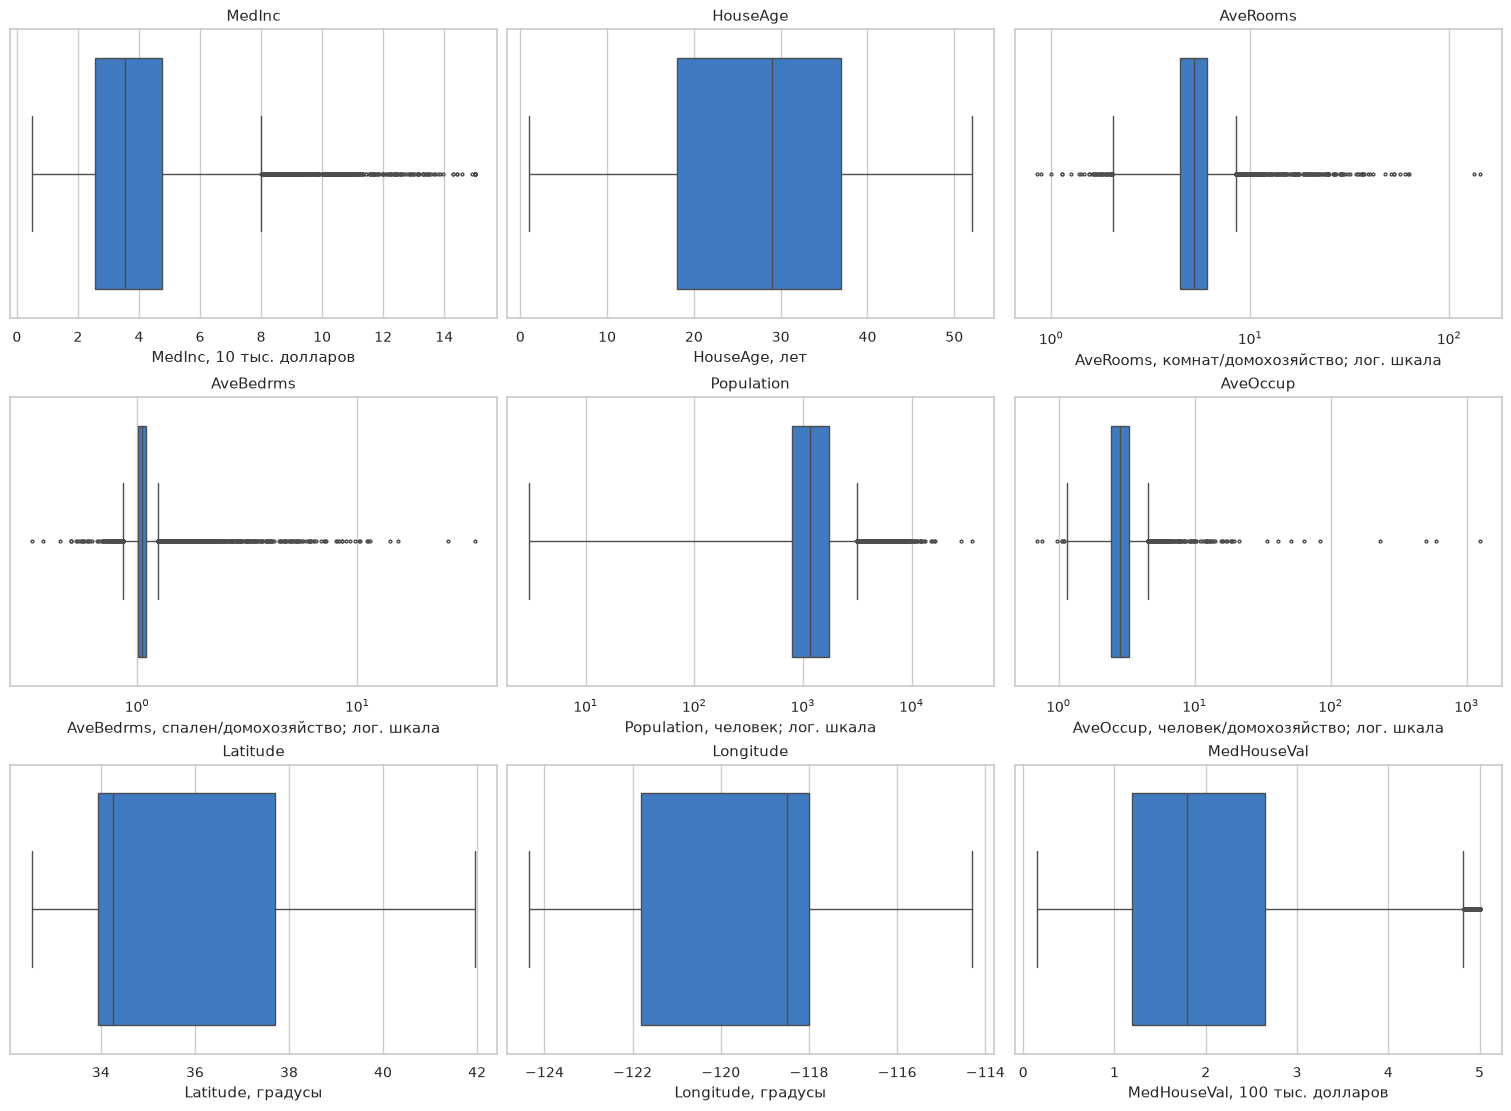

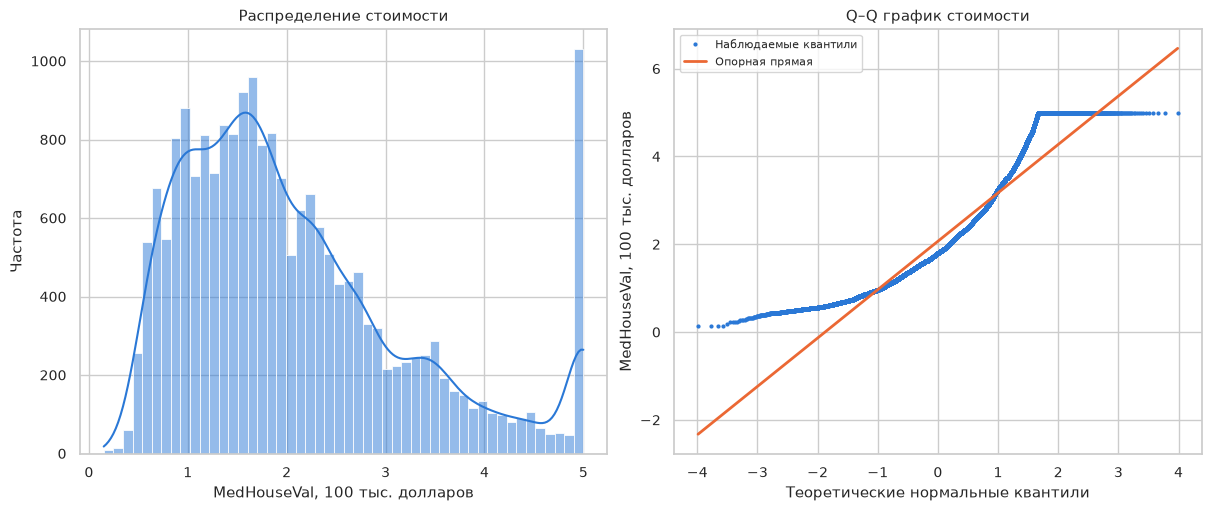

Критерий Д’Агостино–Пирсона: статистика 2430.9310510660694 p-value 0.0
Нормальность при alpha=0.05: отвергается
Верхняя граница стоимости: 5.00001 ; наблюдений на ней: 965


In [3]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12), constrained_layout=True)
for ax, column in zip(axes.flat, original_columns):
    ax.hist(df[column], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_yscale("log")
    ax.set(title=column, xlabel=labels[column], ylabel="Частота, лог. шкала")
save_figure(fig, "01_distributions")

fig, axes = plt.subplots(3, 3, figsize=(15, 11), constrained_layout=True)
for ax, column in zip(axes.flat, original_columns):
    sns.boxplot(x=df[column], ax=ax, color=BLUE, fliersize=2, linewidth=1)
    logarithmic = column in ["AveRooms", "AveBedrms", "Population", "AveOccup"]
    if logarithmic:
        ax.set_xscale("log")
    ax.set(title=column, xlabel=labels[column] + ("; лог. шкала" if logarithmic else ""), ylabel="")
save_figure(fig, "02_boxplots")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
sns.histplot(df.MedHouseVal, bins=50, kde=True, ax=axes[0], color=BLUE)
axes[0].set(title="Распределение стоимости", xlabel=labels["MedHouseVal"], ylabel="Частота")
stats.probplot(df.MedHouseVal, dist="norm", plot=axes[1])
axes[1].set(title="Q–Q график стоимости", xlabel="Теоретические нормальные квантили", ylabel=labels["MedHouseVal"])
axes[1].lines[0].set(color=BLUE, markersize=2, label="Наблюдаемые квантили")
axes[1].lines[1].set(color=ORANGE, linewidth=2, label="Опорная прямая")
axes[1].legend(fontsize=8)
save_figure(fig, "03_qq_medhouseval")
normality = stats.normaltest(df.MedHouseVal)
print("Критерий Д’Агостино–Пирсона: статистика", normality.statistic, "p-value", normality.pvalue)
print("Нормальность при alpha=0.05:", "отвергается" if normality.pvalue < .05 else "не отвергается")
print("Верхняя граница стоимости:", df.MedHouseVal.max(), "; наблюдений на ней:", int(df.MedHouseVal.eq(df.MedHouseVal.max()).sum()))

**Вывод.** У AveRooms, AveBedrms, Population и особенно AveOccup наблюдаются длинные
правые хвосты. Q–Q график стоимости отклоняется от прямой, а тест отвергает
нормальность. При большом объёме выборки тест чувствителен даже к малым отклонениям,
поэтому он рассматривается совместно с графиками. Накопление у верхней границы
MedHouseVal отражает ограничение исходных значений, а не точное равенство рыночных цен.

## 4. Корреляции и парные зависимости
Матрица рассчитывается на полном исходном наборе. Для читаемости парного графика
используется воспроизводимая случайная выборка, отмеченная в его заголовке.

,r с ценой
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


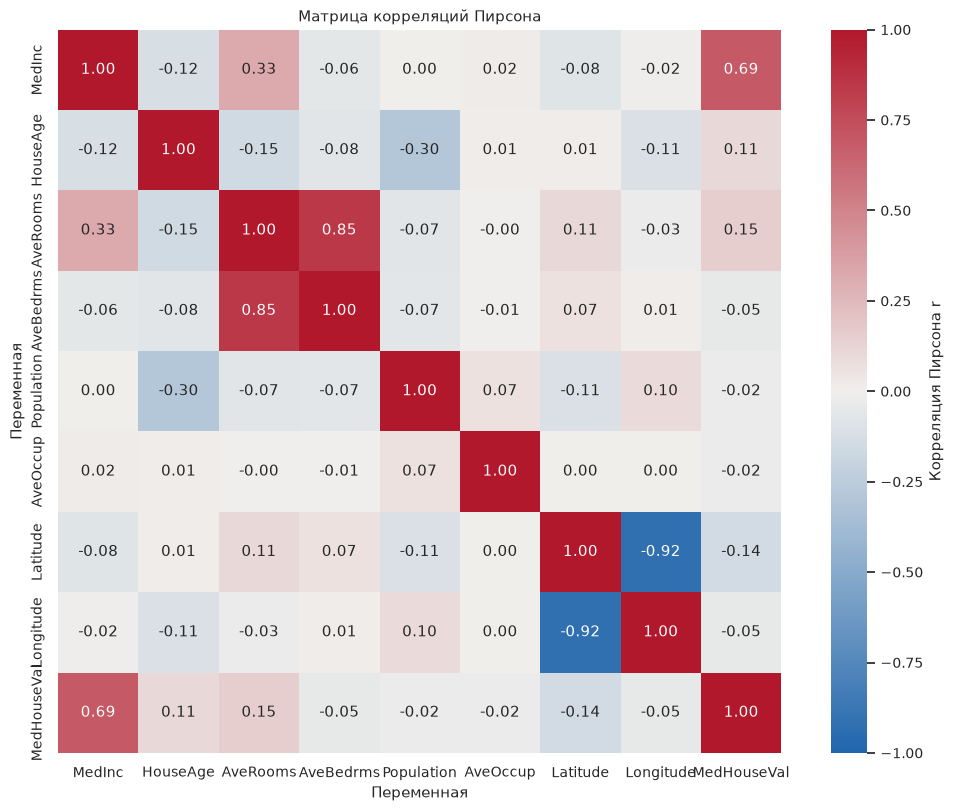

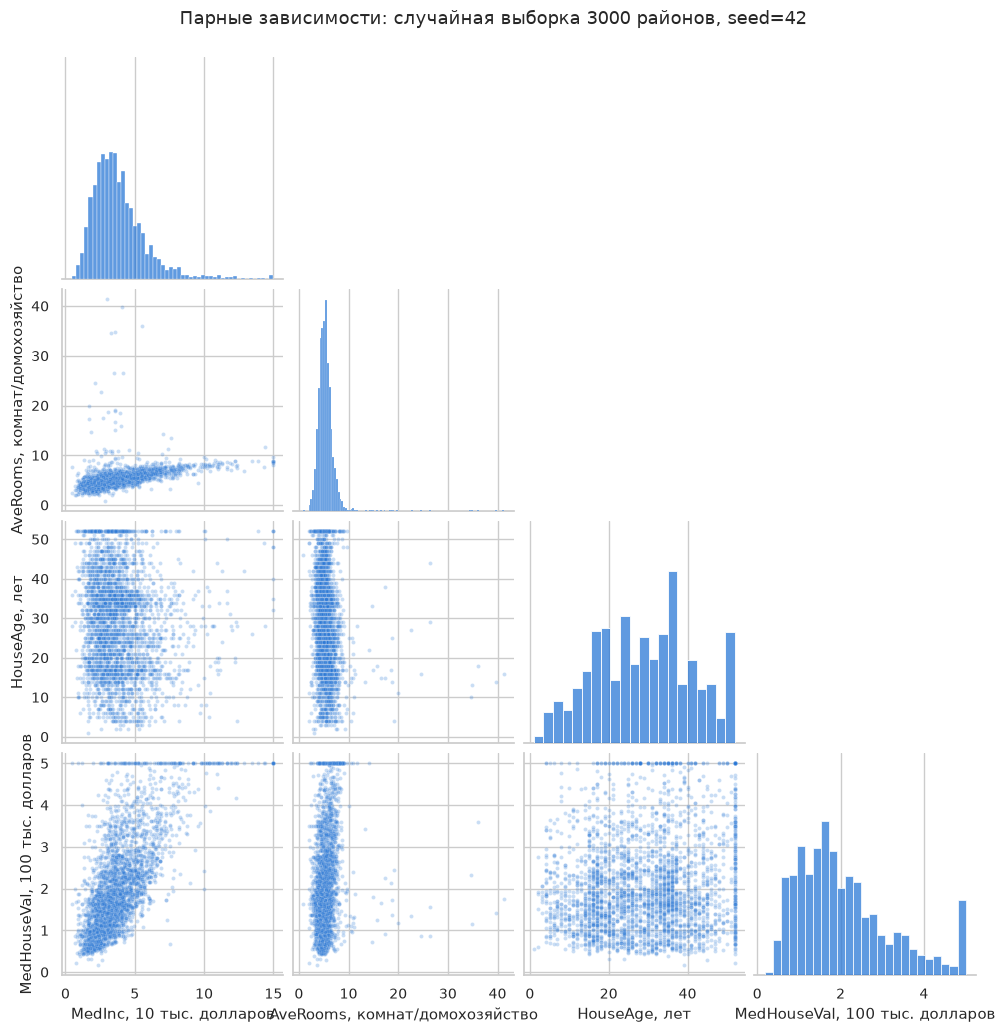

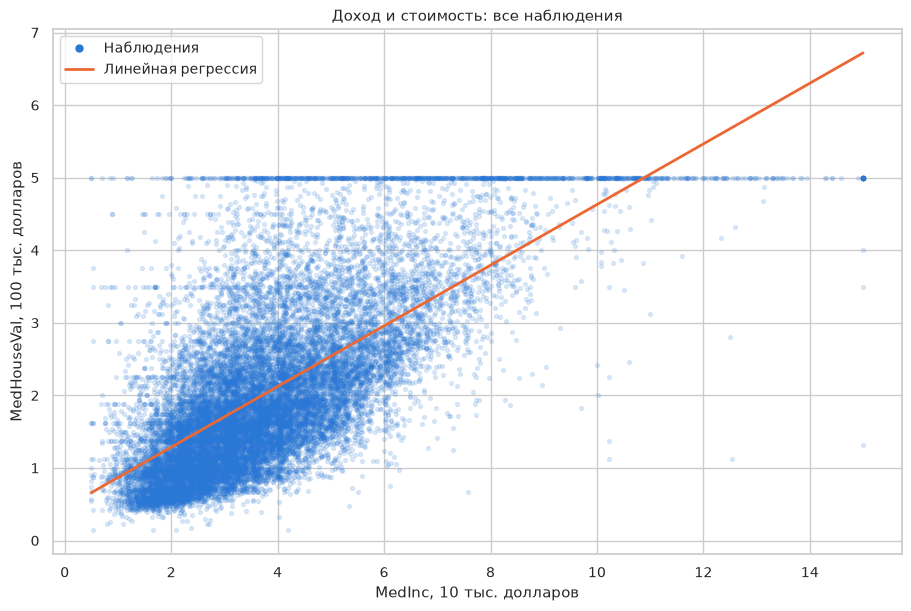

r(доход, стоимость): 0.6880752079585484
r(комнаты, спальни): 0.8476213257130426
r(широта, долгота): -0.9246644339150362


In [4]:
corr = df.corr()
target_correlations = corr.MedHouseVal.drop("MedHouseVal").sort_values(key=abs, ascending=False)
display(target_correlations.rename("r с ценой").to_frame())
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2166ac", "#f0efec", "#b2182b"])
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap=diverging, annot=True, fmt=".2f", square=True, ax=ax, cbar_kws={"label": "Корреляция Пирсона r"})
ax.set(title="Матрица корреляций Пирсона", xlabel="Переменная", ylabel="Переменная")
save_figure(fig, "04_correlation_heatmap")

key = ["MedInc", "AveRooms", "HouseAge", "MedHouseVal"]
sample = df[key].sample(n=3000, random_state=42)
grid = sns.pairplot(sample, corner=True, diag_kind="hist", plot_kws={"s": 8, "alpha": .25, "color": BLUE}, diag_kws={"color": BLUE})
for row in range(len(key)):
    for col in range(len(key)):
        ax = grid.axes[row, col]
        if ax is not None:
            ax.set_xlabel(labels[key[col]] if row == len(key)-1 else "")
            ax.set_ylabel(labels[key[row]] if col == 0 and row != col else ("Частота" if row == col == 0 else ""))
grid.fig.suptitle("Парные зависимости: случайная выборка 3000 районов, seed=42", y=1.03)
save_figure(grid.fig, "05_pairplot")

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
sns.regplot(data=df, x="MedInc", y="MedHouseVal", ci=None, ax=ax,
    scatter_kws={"s": 8, "alpha": .15, "color": BLUE, "label": "Наблюдения"},
    line_kws={"color": ORANGE, "linewidth": 2, "label": "Линейная регрессия"})
ax.set(title="Доход и стоимость: все наблюдения", xlabel=labels["MedInc"], ylabel=labels["MedHouseVal"])
ax.legend(handles=[Line2D([], [], color=BLUE, marker="o", linestyle="None", markersize=5, label="Наблюдения"), Line2D([], [], color=ORANGE, linewidth=2, label="Линейная регрессия")])
save_figure(fig, "06_medinc_price")
print("r(доход, стоимость):", corr.loc["MedInc", "MedHouseVal"])
print("r(комнаты, спальни):", corr.loc["AveRooms", "AveBedrms"])
print("r(широта, долгота):", corr.loc["Latitude", "Longitude"])

**Вывод.** Медианный доход имеет самую сильную линейную связь с ценой. Сильная
корреляция AveRooms–AveBedrms указывает на возможную избыточность признаков.
Также сильно коррелируют Latitude и Longitude из-за пространственной конфигурации
Калифорнии. Для линейной модели следует проверить мультиколлинеарность, например
по VIF, и оценить устойчивость коэффициентов. Здесь модель оценки цен не строится.

## 5. Пространственные закономерности
Малые парные корреляции отдельных координат не исключают нелинейных пространственных
закономерностей. Ниже показаны все районы, цвет обозначает медианную стоимость.
Границы штата и береговая линия не подгружаются; это диаграмма координат, не картографическая подложка.

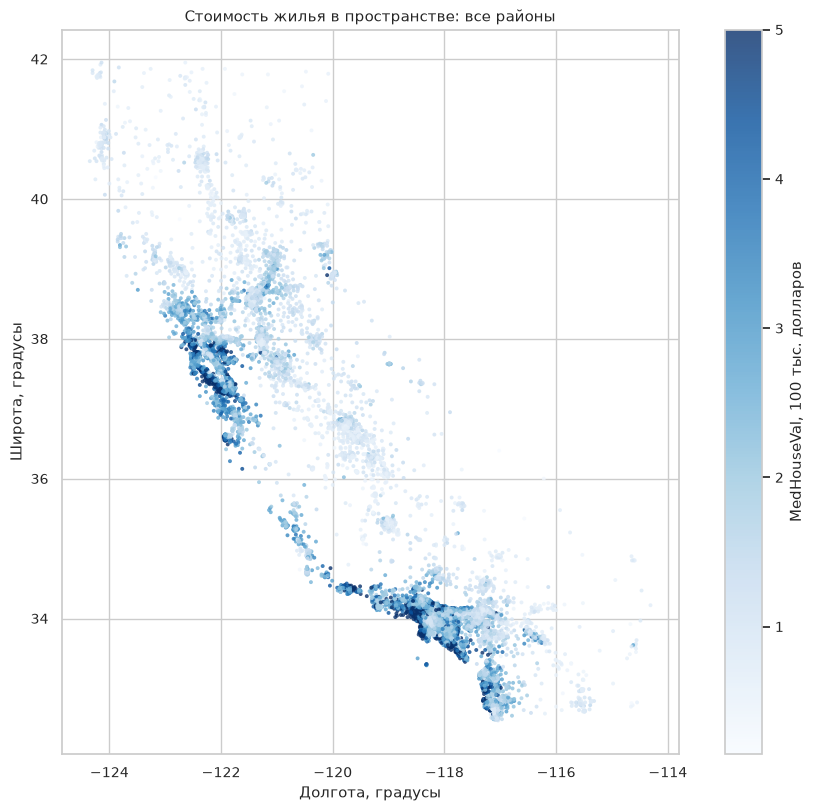

In [5]:
fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
spatial_order = df.sample(frac=1, random_state=42)
scatter = ax.scatter(spatial_order.Longitude, spatial_order.Latitude, c=spatial_order.MedHouseVal,
    cmap="Blues", s=8, alpha=.8, linewidths=0, rasterized=True, vmin=df.MedHouseVal.min(), vmax=df.MedHouseVal.max())
ax.set(title="Стоимость жилья в пространстве: все районы", xlabel="Долгота, градусы", ylabel="Широта, градусы")
ax.set_aspect(1 / np.cos(np.deg2rad(37)))
fig.colorbar(scatter, ax=ax, label="MedHouseVal, 100 тыс. долларов")
save_figure(fig, "08_spatial")

**Вывод.** Более дорогие районы образуют пространственные скопления, в том числе
в западной прибрежной части выборки; одни линейные коэффициенты для координат
этого не описывают. Диаграмма подтверждает неоднородность цен по расположению,
но не устанавливает её причины и не заменяет пространственную модель.

## 6. Обнаружение и обработка выбросов
Выбросы определяются по правилу IQR и по модулю Z-оценки с порогом 3.
Исходные индексы сохранены, нумерация начинается с нуля.

IQR: [2.023219, 8.469878]; выбросов 511
Ниже границы: 45; выше: 466
Z-метод, |z| > 3: 133


,AveRooms,AveOccup,Latitude,Longitude,MedHouseVal
index,,,,,
1914,141.909091,2.727273,38.91,-120.10,5.00001
1979,132.533333,2.400000,38.80,-120.08,1.62500
12447,62.422222,1.844444,33.97,-114.49,0.87500
5916,0.846154,1.846154,34.28,-118.44,1.62500
19006,3.166667,1243.333333,38.32,-121.98,1.37500


,min,max,mean,std,skewness
name,,,,,
original,0.846154,141.909091,5.429000,2.474173,20.697869
winsorized,2.581006,10.359649,5.334211,1.321745,0.816510
log1p,0.613104,4.962209,1.828722,0.231938,1.390761


Порог снизу: 2.5810055865921786 ; сверху: 10.359649122807017 ; изменено: 412


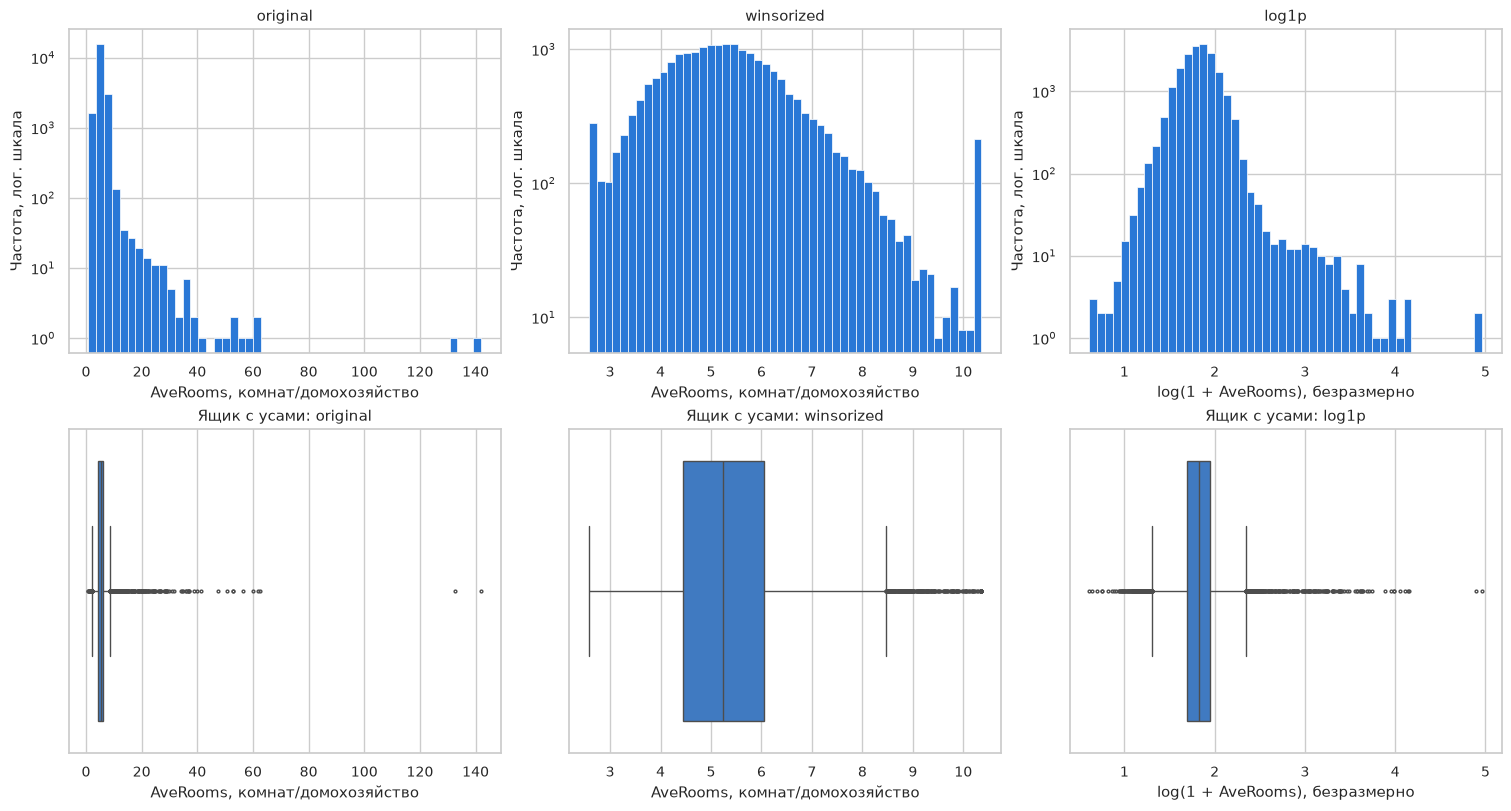

In [6]:
q1, q3 = df.AveRooms.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_mask = (df.AveRooms < lower) | (df.AveRooms > upper)
z_mask = np.abs(stats.zscore(df.AveRooms)) > 3
print(f"IQR: [{lower:.6f}, {upper:.6f}]; выбросов {iqr_mask.sum()}")
print(f"Ниже границы: {(df.AveRooms < lower).sum()}; выше: {(df.AveRooms > upper).sum()}")
print(f"Z-метод, |z| > 3: {z_mask.sum()}")
anomaly_columns = ["AveRooms", "AveOccup", "Latitude", "Longitude", "MedHouseVal"]
example_indices = list(df.AveRooms.nlargest(3).index) + [df.AveRooms.idxmin(), df.AveOccup.idxmax()]
anomalies = df.loc[example_indices, anomaly_columns].copy()
anomalies.index.name = "index"
display(anomalies)
df.loc[iqr_mask, anomaly_columns].to_csv(BASE / "outliers_ave_rooms.csv", index_label="index")

# SciPy заменяет по floor(0.01*n) наблюдений с каждого края на порядковые пороги.
processed = pd.DataFrame({"original": df.AveRooms,
    "winsorized": np.asarray(winsorize(df.AveRooms.to_numpy().copy(), limits=(.01,.01))),
    "log1p": np.log1p(df.AveRooms)})
transformation_summary = processed.describe().T[["min", "max", "mean", "std"]]
transformation_summary["skewness"] = processed.skew()
transformation_summary.index.name = "name"
display(transformation_summary)
changed = int((processed.winsorized != df.AveRooms).sum())
print("Порог снизу:", processed.winsorized.min(), "; сверху:", processed.winsorized.max(), "; изменено:", changed)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for j, column in enumerate(processed):
    values = processed[column]
    unit = "log(1 + AveRooms), безразмерно" if column == "log1p" else labels["AveRooms"]
    axes[0,j].hist(values, bins=50, color=BLUE, edgecolor="white", linewidth=.5)
    axes[0,j].set_yscale("log")
    axes[0,j].set(title=column, xlabel=unit, ylabel="Частота, лог. шкала")
    sns.boxplot(x=values, ax=axes[1,j], color=BLUE, fliersize=2)
    axes[1,j].set(title=f"Ящик с усами: {column}", xlabel=unit, ylabel="")
save_figure(fig, "07_ave_rooms_treatment")
assert df.columns.tolist() == original_columns  # Исходный набор не изменён.

**Вывод.** Редкие большие отношения числа комнат к числу домохозяйств могут быть
связаны с особенностями заселения района. Их нельзя объявлять ошибками только по
статистическому порогу. Например, экстремальный AveOccup требует отдельной проверки.
Без дополнительных сведений наблюдения сохраняются. Винсоризация ограничивает
хвосты, а log1p сжимает масштаб; эффективность сравнивается по вычисленной таблице,
а не только по внешнему виду гистограмм. Преобразования показаны для AveRooms,
исходные столбцы не заменялись.

## 7. Итоговые выводы и сохранение результатов
Таблицы, изображения и числовые результаты сохраняются непосредственно из
выполненных ячеек. Автоматический профилирующий отчёт в методичке необязателен;
здесь HTML экспортируется из этого выполненного ноутбука.

In [7]:
results = {
    "dataset": {"rows": int(df.shape[0]), "columns": int(df.shape[1]),
        "missing_values": int(df.isna().sum().sum()), "duplicates": int(df.duplicated().sum()),
        "source": "sklearn.datasets.fetch_california_housing (local cache)", "year": 1990},
    "stats": summary.to_dict(orient="index"),
    "stats_rows": summary.rename_axis("name").reset_index().to_dict(orient="records"),
    "correlations": corr.to_dict(),
    "target_correlations": target_correlations.to_dict(),
    "feature_pair_corr": float(corr.loc["AveRooms", "AveBedrms"]),
    "ave_rooms_iqr": {"q1": float(q1), "q3": float(q3), "iqr": float(iqr),
        "lower": float(lower), "upper": float(upper), "count": int(iqr_mask.sum()),
        "lower_count": int((df.AveRooms < lower).sum()), "upper_count": int((df.AveRooms > upper).sum())},
    "ave_rooms_z": {"threshold": 3, "count": int(z_mask.sum()), "std_population": float(df.AveRooms.std(ddof=0))},
    "winsorization": {"method": "scipy.stats.mstats.winsorize; inclusive=(True, True)",
        "lower_1pct": float(processed.winsorized.min()), "upper_99pct": float(processed.winsorized.max()), "changed_count": changed},
    "anomalies": anomalies.reset_index().to_dict(orient="records"),
    "transformations": transformation_summary.reset_index().to_dict(orient="records"),
    "target_max_count": int(df.MedHouseVal.eq(df.MedHouseVal.max()).sum()),
    "normality": {"test": "D'Agostino-Pearson", "statistic": float(normality.statistic), "p_value": float(normality.pvalue)},
    "conventions": {"std_ddof": 1, "skewness": "pandas unbiased", "excess_kurtosis": "pandas unbiased Fisher", "quantiles": "linear"},
    "versions": {name: importlib.metadata.version(name) for name in ["pandas","numpy","scipy","scikit-learn","matplotlib","seaborn"]},
}
(BASE / "analysis_results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(Markdown(f"""### Ответы на задачи анализа
1. Изучены **{len(df)}** районов и **{len(df.columns)}** числовых переменных; таблица статистик содержит средние, медианы, разброс и квартили.
2. Пропусков **{df.isna().sum().sum()}**; заполнение не требовалось.
3. Выражены правые хвосты у средних характеристик помещений и заселения; нормальность стоимости отвергается.
4. Для AveRooms выявлено **{iqr_mask.sum()}** выбросов IQR и **{z_mask.sum()}** по Z; конкретные индексы приведены выше.
5. Сильны связи AveRooms–AveBedrms (**{corr.loc['AveRooms','AveBedrms']:.4f}**) и Latitude–Longitude (**{corr.loc['Latitude','Longitude']:.4f}**); это повод проверить мультиколлинеарность.
6. Сильнее всего с ценой линейно связан MedInc: **r = {target_correlations['MedInc']:.4f}**. Это связь, а не доказательство причинности.
7. Диаграмма координат выявляет пространственную неоднородность; слабые корреляции отдельных координат не исключают нелинейную структуру.

Для моделирования следует сохранить исходные данные, обосновать обработку аномалий, рассмотреть нелинейные пространственные признаки и проверять результаты на отложенных данных."""))

### Ответы на задачи анализа
1. Изучены **20640** районов и **9** числовых переменных; таблица статистик содержит средние, медианы, разброс и квартили.
2. Пропусков **0**; заполнение не требовалось.
3. Выражены правые хвосты у средних характеристик помещений и заселения; нормальность стоимости отвергается.
4. Для AveRooms выявлено **511** выбросов IQR и **133** по Z; конкретные индексы приведены выше.
5. Сильны связи AveRooms–AveBedrms (**0.8476**) и Latitude–Longitude (**-0.9247**); это повод проверить мультиколлинеарность.
6. Сильнее всего с ценой линейно связан MedInc: **r = 0.6881**. Это связь, а не доказательство причинности.
7. Диаграмма координат выявляет пространственную неоднородность; слабые корреляции отдельных координат не исключают нелинейную структуру.

Для моделирования следует сохранить исходные данные, обосновать обработку аномалий, рассмотреть нелинейные пространственные признаки и проверять результаты на отложенных данных.

## Приложение. Воспроизводимость
Все кодовые ячейки выполнены сверху вниз; графики встроены в выводы и сохранены в
`figures`. Полная таблица описательных статистик сохранена в `descriptive_statistics.csv`,
список IQR-выбросов — в `outliers_ave_rooms.csv`, результаты — в `analysis_results.json`.
Локальный кэш `data/sklearn_cache` позволяет повторить вычисления без сети.
В `requirements.txt` записаны фактически использованные версии библиотек.